In [5]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten,Input
from tensorflow.keras.optimizers import SGD

In [6]:
train_data=pd.read_csv('mnist_train.csv')
test_data=pd.read_csv('mnist_test.csv')
y_train=train_data['label'].values
x_train=train_data.drop('label',axis=1).values

y_test=test_data['label'].values
x_test=test_data.drop('label',axis=1).values

In [7]:
x_train=x_train/255.0
x_test=x_test/255.0

x_train=x_train.reshape(-1,28,28)
x_test=x_test.reshape(-1,28,28)

In [8]:
model=Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])

In [9]:
model.compile(optimizer=SGD(learning_rate=0.01),
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])
history=model.fit(
    x_train,y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8252 - loss: 0.6977 - val_accuracy: 0.9187 - val_loss: 0.3269
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9036 - loss: 0.3505 - val_accuracy: 0.9312 - val_loss: 0.2594
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9166 - loss: 0.2993 - val_accuracy: 0.9390 - val_loss: 0.2309
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9261 - loss: 0.2686 - val_accuracy: 0.9422 - val_loss: 0.2092
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9323 - loss: 0.2454 - val_accuracy: 0.9460 - val_loss: 0.1950
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9365 - loss: 0.2270 - val_accuracy: 0.9498 - val_loss: 0.1814
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9408 - loss: 0.2117 - val_accuracy: 0.9555 - val_loss: 0.1704
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9447 - loss: 0.1985 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9536 - loss: 0.1613
Test Loss: 0.16125671565532684
Test Accuracy: 95.35999894142151 %


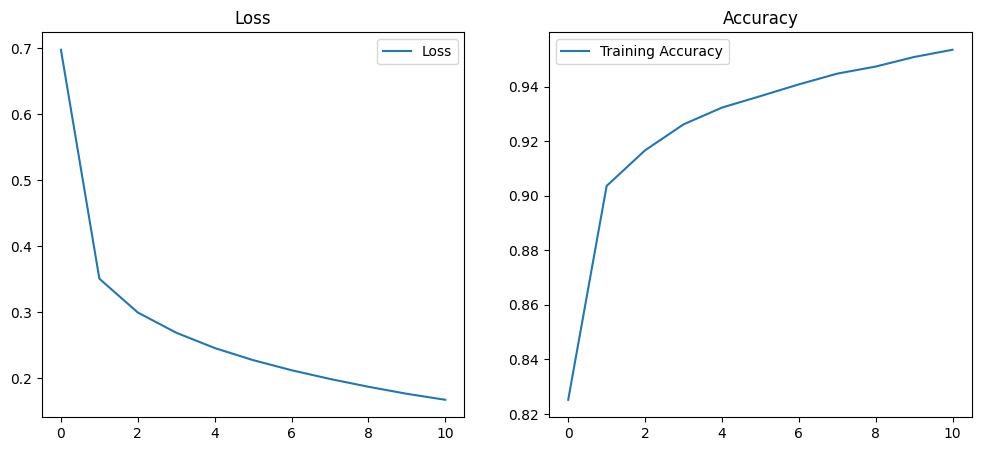

In [10]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print('Test Loss:',test_loss)
print('Test Accuracy:',test_accuracy*100,'%')

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Loss')
plt.title('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.title('Accuracy')
plt.legend()
plt.show()